In [2]:
from collections import Counter
import pandas as pd
from sklearn.mixture import GaussianMixture
import numpy as np
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.metrics import calinski_harabasz_score
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler



data = pd.read_excel(r"E:\desktop\Multiobjective Identification of Phosphor Materials via a Domain Knowledge Integrated Semisupervised Learning Framework\dataset\stage4\296×87.xlsx")
X = data.iloc[:, 3:]
X
feature_names = X.columns
X = StandardScaler().fit_transform(X)

min_val = np.min(X, axis=0)
max_val = np.max(X, axis=0)
X = (X - min_val) / (max_val - min_val)
imputer = SimpleImputer(strategy="mean")
X = imputer.fit_transform(X)
X.shape

(296, 87)

In [3]:

def extract_numbers(file_path):
    df = pd.read_excel(file_path)
    valid_numbers = []
    for index, value in df['composition'].items():
        if not pd.isna(value):
            valid_numbers.append(int(df.at[index, 'number']))
    return valid_numbers


file_path = r"E:\desktop\Multiobjective Identification of Phosphor Materials via a Domain Knowledge Integrated Semisupervised Learning Framework\dataset\stage4\benchmark4.xlsx"
reported_structures = extract_numbers(file_path)
# print(reported_structures)

for j in range(30, 100, 5):
    j = j/100

    pca = PCA(n_components= j)
    pca_data = pca.fit_transform(X)
    num_pca = pca_data.shape[1]

    for i in range(3, 7):
        GMM = GaussianMixture(n_components=i, covariance_type='tied', init_params = 'random', reg_covar= 1e-5, tol  =  1e-5 , random_state=42)
        GMM.fit(pca_data)
        labels = GMM.predict(pca_data)
        if len(np.unique(labels)) > 1:
            #silhouette_avg = silhouette_score(new_data, labels)
            #calinski_harabasz_avg = calinski_harabasz_score(new_data, labels)
            print(f"\nNumber of clusters k={i}:", f"\nPCA retained variance={j}:", f"\nSilhouette score: {silhouette_score(pca_data, labels):.2f}", f"\nCalinski-Harabasz score: {calinski_harabasz_score(pca_data, labels):.2f}")
        else:
            pass

        data[f'cluster_{i}'] = labels
        dict = {}

        label_1 = []
        for num  in  reported_structures:
            label = labels[num-1]
            label_1.append(int(label))
        print(label_1)

        for cluster in range(i):

            cluster_samples = data[data[f'cluster_{i}'] == cluster]
                # print(cluster_samples)

            total_in_cluster = len(cluster_samples)


            reported_in_cluster = len([num for num in cluster_samples['number'] if num in reported_structures])
            dict[cluster] = (reported_in_cluster, total_in_cluster)
        for value in dict.values():
            if value[0] == 0:
                for key, value in dict.items():

                    formatted_value = f"{value[0]}/{value[1]}"

                    print(f"Cluster {key}: {formatted_value}")
                    #print(f"Cluster {cluster}: {reported_in_cluster}/{total_in_cluster} "
                    #    f"(Reported ratio: {reported_in_cluster/total_in_cluster:.2%})")


Number of clusters k=3: 
PCA retained variance=0.3: 
Silhouette score: 0.42 
Calinski-Harabasz score: 257.79
[0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0]
Cluster 0: 8/154
Cluster 1: 7/127
Cluster 2: 0/15

Number of clusters k=4: 
PCA retained variance=0.3: 
Silhouette score: 0.29 
Calinski-Harabasz score: 155.74
[0, 3, 1, 3, 0, 3, 3, 3, 3, 3, 0, 3, 2, 1, 0]

Number of clusters k=5: 
PCA retained variance=0.3: 
Silhouette score: 0.36 
Calinski-Harabasz score: 226.22
[0, 0, 0, 2, 0, 2, 2, 1, 2, 2, 0, 2, 1, 1, 0]
Cluster 0: 6/78
Cluster 1: 3/115
Cluster 2: 6/103
Cluster 3: 0/0
Cluster 4: 0/0
Cluster 0: 6/78
Cluster 1: 3/115
Cluster 2: 6/103
Cluster 3: 0/0
Cluster 4: 0/0

Number of clusters k=6: 
PCA retained variance=0.3: 
Silhouette score: 0.24 
Calinski-Harabasz score: 115.64
[5, 3, 3, 1, 3, 1, 1, 1, 1, 3, 3, 1, 1, 3, 5]
Cluster 0: 0/0
Cluster 1: 7/150
Cluster 2: 0/12
Cluster 3: 6/94
Cluster 4: 0/0
Cluster 5: 2/40
Cluster 0: 0/0
Cluster 1: 7/150
Cluster 2: 0/12
Cluster 3: 6/94
Cluster

c:\Users\Administrator\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\mixture\_base.py:275: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(



Number of clusters k=3: 
PCA retained variance=0.85: 
Silhouette score: 0.05 
Calinski-Harabasz score: 22.36
[0, 1, 0, 1, 2, 1, 0, 1, 1, 1, 0, 1, 2, 0, 0]

Number of clusters k=4: 
PCA retained variance=0.85: 
Silhouette score: 0.06 
Calinski-Harabasz score: 14.18
[3, 3, 2, 3, 0, 3, 3, 3, 3, 3, 3, 0, 3, 3, 3]
Cluster 0: 2/40
Cluster 1: 0/8
Cluster 2: 1/47
Cluster 3: 12/201

Number of clusters k=5: 
PCA retained variance=0.85: 
Silhouette score: 0.05 
Calinski-Harabasz score: 16.20
[4, 0, 1, 0, 0, 0, 4, 0, 0, 0, 4, 0, 4, 0, 4]
Cluster 0: 9/155
Cluster 1: 1/45
Cluster 2: 0/8
Cluster 3: 0/7
Cluster 4: 5/81
Cluster 0: 9/155
Cluster 1: 1/45
Cluster 2: 0/8
Cluster 3: 0/7
Cluster 4: 5/81

Number of clusters k=6: 
PCA retained variance=0.85: 
Silhouette score: 0.04 
Calinski-Harabasz score: 15.40
[4, 2, 3, 2, 2, 2, 5, 2, 2, 5, 5, 2, 2, 2, 5]
Cluster 0: 0/8
Cluster 1: 0/11
Cluster 2: 9/110
Cluster 3: 1/46
Cluster 4: 1/23
Cluster 5: 4/98
Cluster 0: 0/8
Cluster 1: 0/11
Cluster 2: 9/110
Cluster 3

c:\Users\Administrator\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\mixture\_base.py:275: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(



Number of clusters k=6: 
PCA retained variance=0.9: 
Silhouette score: 0.03 
Calinski-Harabasz score: 10.10
[4, 5, 2, 5, 4, 5, 5, 5, 5, 1, 4, 5, 5, 5, 1]
Cluster 0: 0/8
Cluster 1: 2/21
Cluster 2: 1/49
Cluster 3: 0/9
Cluster 4: 3/46
Cluster 5: 9/163
Cluster 0: 0/8
Cluster 1: 2/21
Cluster 2: 1/49
Cluster 3: 0/9
Cluster 4: 3/46
Cluster 5: 9/163

Number of clusters k=3: 
PCA retained variance=0.95: 
Silhouette score: 0.02 
Calinski-Harabasz score: 7.78
[0, 1, 2, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0]

Number of clusters k=4: 
PCA retained variance=0.95: 
Silhouette score: 0.05 
Calinski-Harabasz score: 13.35
[3, 0, 3, 3, 0, 3, 3, 3, 3, 3, 3, 0, 3, 3, 3]
Cluster 0: 3/43
Cluster 1: 0/7
Cluster 2: 0/31
Cluster 3: 12/215
Cluster 0: 3/43
Cluster 1: 0/7
Cluster 2: 0/31
Cluster 3: 12/215

Number of clusters k=5: 
PCA retained variance=0.95: 
Silhouette score: 0.12 
Calinski-Harabasz score: 30.00
[3, 3, 3, 0, 3, 0, 0, 0, 0, 4, 3, 0, 3, 3, 3]
Cluster 0: 6/109
Cluster 1: 0/17
Cluster 2: 0/13
Cluster 3

In [4]:
pca = PCA(n_components= 0.7, random_state=42)
new_data = pca.fit_transform(X)
print(new_data.shape)
ratios = pca.explained_variance_ratio_
components = pca.components_
X = pd.DataFrame(X)

components_df = pd.DataFrame(
    components,
    columns=X.columns,
    index=[f"PC{i+1}" for i in range(components.shape[0])]
)

output_file = "pca_components.xlsx"
components_df.to_excel(output_file, index=True)


i = 5
GMM = GaussianMixture(n_components=i, covariance_type='full', init_params = 'random', reg_covar= 1e-5, tol  =  1e-4 , random_state=42)
GMM.fit(new_data)
labels = GMM.predict(new_data)
print(f"Silhouette score: {silhouette_score(new_data, labels):.2f}")
print(f"Calinski-Harabasz score: {calinski_harabasz_score(new_data, labels):.2f}")
df = pd.DataFrame(labels)
df.to_excel("GMM_result.xlsx")

data[f'cluster_{i}'] = labels

print(f"\nNumber of clusters k={i}:")


for cluster in range(i):

    cluster_samples = data[data[f'cluster_{i}'] == cluster]
            # print(cluster_samples)

    total_in_cluster = len(cluster_samples)

    reported_in_cluster = len([num for num in cluster_samples['number'] if num in reported_structures])

    print(f"Cluster {cluster}: {reported_in_cluster}/{total_in_cluster} "
                f"(Reported ratio: {reported_in_cluster/total_in_cluster:.2%})")

(296, 10)
Silhouette score: 0.08
Calinski-Harabasz score: 33.72

Number of clusters k=5:
Cluster 0: 0/44 (Reported ratio: 0.00%)
Cluster 1: 0/37 (Reported ratio: 0.00%)
Cluster 2: 7/82 (Reported ratio: 8.54%)
Cluster 3: 0/18 (Reported ratio: 0.00%)
Cluster 4: 8/115 (Reported ratio: 6.96%)


In [5]:
import pandas as pd
from sklearn.decomposition import PCA
from openpyxl.styles import Font
from openpyxl.utils.dataframe import dataframe_to_rows
from openpyxl import Workbook


wb = Workbook()
ws = wb.active


for r in dataframe_to_rows(components_df, index=True, header=True):
    ws.append(r)


red_bold_font = Font(color="FF0000", bold=True)


for row in range(2, ws.max_row + 1):

    values = [ws.cell(row=row, column=col).value for col in range(2, ws.max_column + 1)]


    values = [0 if v is None else v for v in values]


    abs_values = [abs(v) for v in values]
    top_10_indices = sorted(range(len(abs_values)), key=lambda i: abs_values[i], reverse=True)[:10]


    for idx in top_10_indices:
        ws.cell(row=row, column=idx + 2).font = red_bold_font


output_file = "pca_components_highlighted.xlsx"
wb.save(output_file)

print(f"The component-loading matrix has been saved to {output_file}, with the 10 largest absolute values highlighted.")

The component-loading matrix has been saved to pca_components_highlighted.xlsx, with the 10 largest absolute values highlighted.


## 15 benchmark Euclidean distance

### 
1. ****： notebook  `PCA(n_components=0.65)`， 8  PCA ， `GMM(n_components=6, covariance_type='tied')` 。，benchmark  8  PCA ， 15  benchmark  PCA， 87 。
2. ** 15  benchmark**： `reported_structures` ， `data` ， benchmark 。
3. **Euclidean distance**： benchmark $i,j$，
   $d_{ij}=\sqrt{\sum_k(z_{ik}-z_{jk})^2}$， $z$  PCA 。15  benchmark  $15\times14/2=105$ 。
4. ****： 105  benchmark  GMM cluster  cluster，“”。
5. ** Excel**：、105 、benchmark  PCA  cluster ， cluster 。
6. ****：pairwise distance 。“”（ $-\log_{10}p$），Euclidean distance， 15×15 Euclidean distance，。



 benchmark PCA ：10
Benchmark ：15

Euclidean distance：2.768577
Normalized：0.0000 – 1.0000

Excel ：E:\desktop\Multiobjective Identification of Phosphor Materials via a Domain Knowledge Integrated Semisupervised Learning Framework\code\Prototype-base-cluster\GMM\GMM4\benchmark_distance_output\15_benchmark_pairwise_euclidean_distance_normalized.xlsx


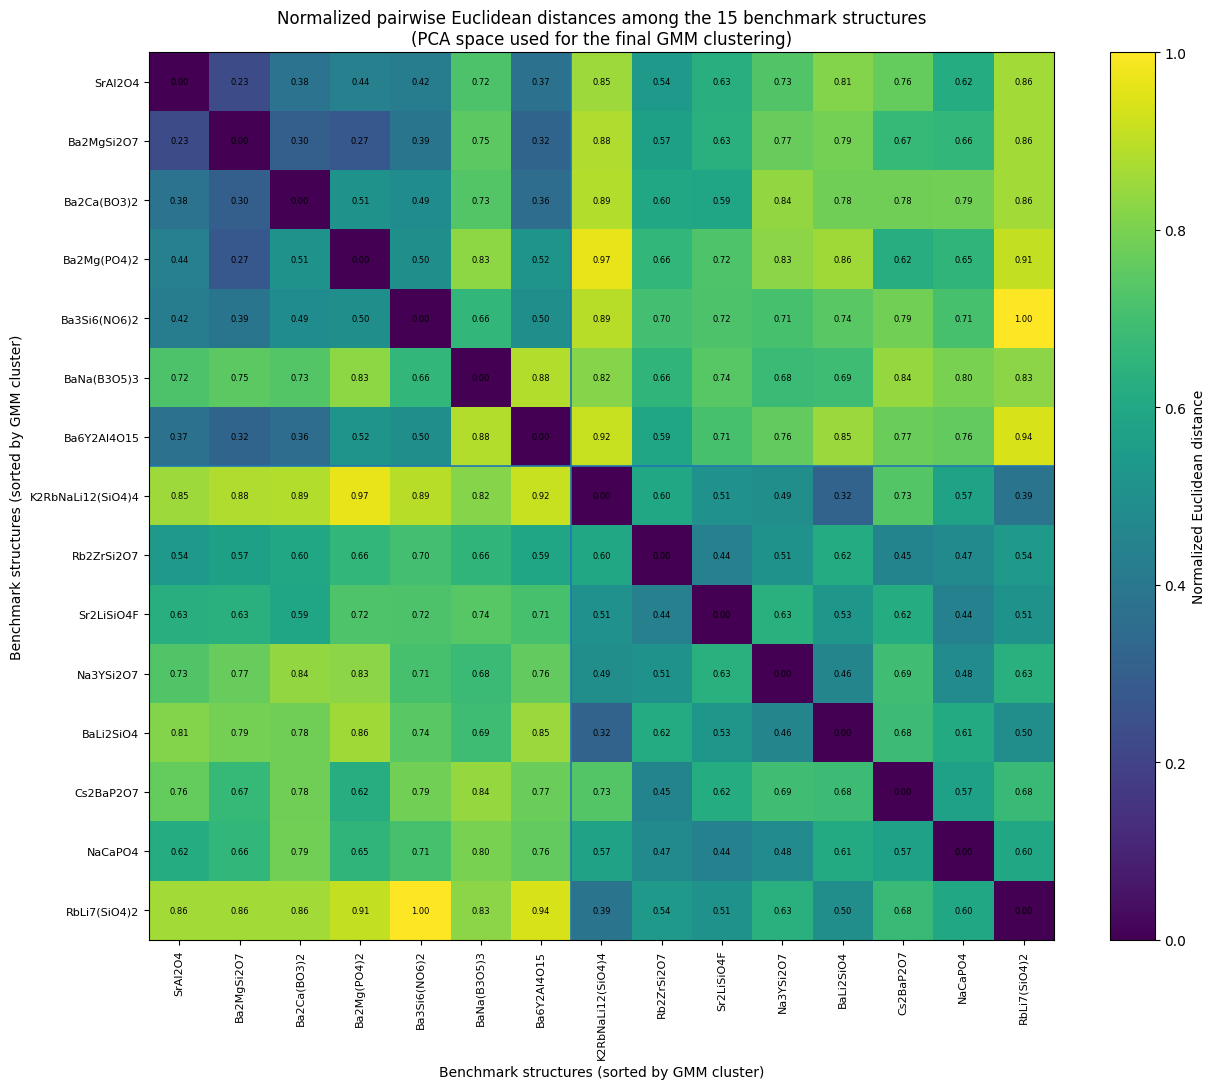


Normalized：E:\desktop\Multiobjective Identification of Phosphor Materials via a Domain Knowledge Integrated Semisupervised Learning Framework\code\Prototype-base-cluster\GMM\GMM4\benchmark_distance_output\15_benchmark_normalized_euclidean_distance_heatmap.png

Pairwise distance 10：


,Pair_Rank_From_Nearest,Benchmark_A_Number,Benchmark_A_Composition,Cluster_A,Benchmark_B_Number,Benchmark_B_Composition,Cluster_B,Same_Cluster,Euclidean_Distance,Normalized_Euclidean_Distance
0,1,17,SrAl2O4,2,111,Ba2MgSi2O7,2,True,0.638898,0.230768
1,2,111,Ba2MgSi2O7,2,144,Ba2Mg(PO4)2,2,True,0.757432,0.273582
2,3,111,Ba2MgSi2O7,2,142,Ba2Ca(BO3)2,2,True,0.833045,0.300893
3,4,14,K2RbNaLi12(SiO4)4,4,171,BaLi2SiO4,4,True,0.886066,0.320044
4,5,111,Ba2MgSi2O7,2,180,Ba6Y2Al4O15,2,True,0.890896,0.321789
5,6,142,Ba2Ca(BO3)2,2,180,Ba6Y2Al4O15,2,True,0.989389,0.357364
6,7,17,SrAl2O4,2,180,Ba6Y2Al4O15,2,True,1.032134,0.372803
7,8,17,SrAl2O4,2,142,Ba2Ca(BO3)2,2,True,1.053915,0.380670
8,9,14,K2RbNaLi12(SiO4)4,4,283,RbLi7(SiO4)2,4,True,1.069185,0.386186
9,10,111,Ba2MgSi2O7,2,153,Ba3Si6(NO6)2,2,True,1.074230,0.388008


In [6]:

from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import pairwise_distances


required_vars = ['data', 'reported_structures', 'new_data', 'labels']

missing_vars = [
    v for v in required_vars
    if v not in globals()
]

if missing_vars:
    raise RuntimeError(
        f" {missing_vars}。"
        "、benchmark。"
    )

if len(reported_structures) != 15:
    raise ValueError(
        f" reported_structures  "
        f"{len(reported_structures)} ，"
        "15。"
    )

if len(new_data) != len(data) or len(labels) != len(data):
    raise ValueError(
        "new_data / labels  data ，"
        "Clustering result。"
    )


# ============================================================

# ============================================================

number_series = pd.to_numeric(
    data['number'],
    errors='coerce'
)

benchmark_row_indices = []

for num in reported_structures:

    hit = np.flatnonzero(
        number_series.to_numpy() == int(num)
    )

    if len(hit) == 0:
        raise ValueError(
            f" data['number']  "
            f"benchmark number={num}"
        )

    if len(hit) > 1:
        raise ValueError(
            f"benchmark number={num} "
            f" data  {len(hit)} ，"
            "。"
        )

    benchmark_row_indices.append(
        int(hit[0])
    )



benchmark_pca = np.asarray(new_data)[
    benchmark_row_indices, :
]

benchmark_clusters = np.asarray(labels)[
    benchmark_row_indices
]

print(
    f" benchmark PCA ："
    f"{benchmark_pca.shape[1]}"
)

print(
    f"Benchmark ："
    f"{benchmark_pca.shape[0]}"
)


# ============================================================

# ============================================================

composition_map = {}

try:

    benchmark_meta = pd.read_excel(file_path)

    if (
        'number' in benchmark_meta.columns
        and 'composition' in benchmark_meta.columns
    ):

        tmp = benchmark_meta[
            ['number', 'composition']
        ].copy()

        tmp['number'] = pd.to_numeric(
            tmp['number'],
            errors='coerce'
        )

        tmp = (
            tmp
            .dropna(subset=['number'])
            .drop_duplicates('number')
        )

        composition_map = {
            int(row['number']): str(row['composition'])
            for _, row in tmp.iterrows()
            if not pd.isna(row['composition'])
        }

except Exception as e:

    print(
        "： composition ，"
        f" number 。：{e}"
    )


benchmark_compositions = [
    composition_map.get(
        int(n),
        f"No.{int(n)}"
    )
    for n in reported_structures
]


benchmark_labels = [
    f"{int(n)} | {c}"
    for n, c in zip(
        reported_structures,
        benchmark_compositions
    )
]


# ============================================================

# ============================================================

distance_matrix = pairwise_distances(
    benchmark_pca,
    metric='euclidean'
)


np.fill_diagonal(
    distance_matrix,
    0.0
)


distance_df = pd.DataFrame(
    distance_matrix,
    index=benchmark_labels,
    columns=benchmark_labels
)

distance_df.index.name = 'Benchmark'


# ============================================================

# ============================================================



#
# normalized_distance = distance / max(distance)
#



max_distance = np.max(distance_matrix)

if max_distance <= 0:
    raise ValueError(
        "Euclidean distance0，Normalized。"
    )


normalized_distance_matrix = (
    distance_matrix / max_distance
)

np.fill_diagonal(
    normalized_distance_matrix,
    0.0
)


normalized_distance_df = pd.DataFrame(
    normalized_distance_matrix,
    index=benchmark_labels,
    columns=benchmark_labels
)

normalized_distance_df.index.name = 'Benchmark'


print(
    f"\nEuclidean distance："
    f"{max_distance:.6f}"
)

print(
    "Normalized："
    f"{normalized_distance_matrix.min():.4f} "
    "– "
    f"{normalized_distance_matrix.max():.4f}"
)


# ============================================================

# ============================================================

pair_records = []

for i, j in combinations(
    range(len(reported_structures)),
    2
):

    pair_records.append({

        'Benchmark_A_Number':
            int(reported_structures[i]),

        'Benchmark_A_Composition':
            benchmark_compositions[i],

        'Cluster_A':
            int(benchmark_clusters[i]),

        'Benchmark_B_Number':
            int(reported_structures[j]),

        'Benchmark_B_Composition':
            benchmark_compositions[j],

        'Cluster_B':
            int(benchmark_clusters[j]),

        'Same_Cluster':
            bool(
                benchmark_clusters[i]
                == benchmark_clusters[j]
            ),


        'Euclidean_Distance':
            float(
                distance_matrix[i, j]
            ),

        # 0–1NormalizedEuclidean distance
        'Normalized_Euclidean_Distance':
            float(
                normalized_distance_matrix[i, j]
            ),
    })


pairwise_df = pd.DataFrame(
    pair_records
)



pairwise_df = (
    pairwise_df
    .sort_values(
        'Euclidean_Distance',
        ascending=True
    )
    .reset_index(drop=True)
)


pairwise_df.insert(
    0,
    'Pair_Rank_From_Nearest',
    np.arange(
        1,
        len(pairwise_df) + 1
    )
)


# ============================================================

# ============================================================

pc_cols = [
    f'PC{i+1}'
    for i in range(
        benchmark_pca.shape[1]
    )
]


benchmark_info_df = pd.DataFrame(
    benchmark_pca,
    columns=pc_cols
)


benchmark_info_df.insert(
    0,
    'Cluster',
    benchmark_clusters.astype(int)
)


benchmark_info_df.insert(
    0,
    'Composition',
    benchmark_compositions
)


benchmark_info_df.insert(
    0,
    'Number',
    [
        int(x)
        for x in reported_structures
    ]
)


# ============================================================

# ============================================================

sort_order = np.argsort(
    benchmark_clusters,
    kind='stable'
)


sorted_labels = [
    benchmark_labels[k]
    for k in sort_order
]


# -------------------------

# -------------------------

sorted_distance_df = pd.DataFrame(

    distance_matrix[
        np.ix_(
            sort_order,
            sort_order
        )
    ],

    index=sorted_labels,
    columns=sorted_labels
)

sorted_distance_df.index.name = 'Benchmark'


# -------------------------

# -------------------------

sorted_normalized_distance_df = pd.DataFrame(

    normalized_distance_matrix[
        np.ix_(
            sort_order,
            sort_order
        )
    ],

    index=sorted_labels,
    columns=sorted_labels
)

sorted_normalized_distance_df.index.name = 'Benchmark'


# ============================================================

# ============================================================

same_cluster_raw = pairwise_df.loc[
    pairwise_df['Same_Cluster'],
    'Euclidean_Distance'
]

diff_cluster_raw = pairwise_df.loc[
    ~pairwise_df['Same_Cluster'],
    'Euclidean_Distance'
]


same_cluster_norm = pairwise_df.loc[
    pairwise_df['Same_Cluster'],
    'Normalized_Euclidean_Distance'
]

diff_cluster_norm = pairwise_df.loc[
    ~pairwise_df['Same_Cluster'],
    'Normalized_Euclidean_Distance'
]


summary_df = pd.DataFrame({

    'Metric': [

        'Number_of_benchmarks',

        'Number_of_unique_pairs',

        'Maximum_raw_distance',

        'Mean_raw_distance_all_pairs',

        'Median_raw_distance_all_pairs',

        'Mean_raw_distance_same_cluster',

        'Median_raw_distance_same_cluster',

        'Mean_raw_distance_different_cluster',

        'Median_raw_distance_different_cluster',

        'Mean_normalized_distance_all_pairs',

        'Median_normalized_distance_all_pairs',

        'Mean_normalized_distance_same_cluster',

        'Median_normalized_distance_same_cluster',

        'Mean_normalized_distance_different_cluster',

        'Median_normalized_distance_different_cluster',
    ],


    'Value': [

        len(reported_structures),

        len(pairwise_df),

        max_distance,

        pairwise_df[
            'Euclidean_Distance'
        ].mean(),

        pairwise_df[
            'Euclidean_Distance'
        ].median(),

        same_cluster_raw.mean()
        if len(same_cluster_raw)
        else np.nan,

        same_cluster_raw.median()
        if len(same_cluster_raw)
        else np.nan,

        diff_cluster_raw.mean()
        if len(diff_cluster_raw)
        else np.nan,

        diff_cluster_raw.median()
        if len(diff_cluster_raw)
        else np.nan,

        pairwise_df[
            'Normalized_Euclidean_Distance'
        ].mean(),

        pairwise_df[
            'Normalized_Euclidean_Distance'
        ].median(),

        same_cluster_norm.mean()
        if len(same_cluster_norm)
        else np.nan,

        same_cluster_norm.median()
        if len(same_cluster_norm)
        else np.nan,

        diff_cluster_norm.mean()
        if len(diff_cluster_norm)
        else np.nan,

        diff_cluster_norm.median()
        if len(diff_cluster_norm)
        else np.nan,
    ]
})


# ============================================================

# ============================================================

output_dir = (
    Path.cwd()
    / 'benchmark_distance_output'
)

output_dir.mkdir(
    parents=True,
    exist_ok=True
)


excel_path = (
    output_dir
    / '15_benchmark_pairwise_euclidean_distance_normalized.xlsx'
)


with pd.ExcelWriter(
    excel_path,
    engine='openpyxl'
) as writer:


    distance_df.to_excel(
        writer,
        sheet_name='Distance_Matrix'
    )


    normalized_distance_df.to_excel(
        writer,
        sheet_name='Normalized_Distance_Matrix'
    )


    pairwise_df.to_excel(
        writer,
        sheet_name='Pairwise_105',
        index=False
    )


    benchmark_info_df.to_excel(
        writer,
        sheet_name='Benchmark_PCA_Cluster',
        index=False
    )


    sorted_distance_df.to_excel(
        writer,
        sheet_name='Raw_Matrix_Sorted'
    )


    sorted_normalized_distance_df.to_excel(
        writer,
        sheet_name='Normalized_Matrix_Sorted'
    )


    summary_df.to_excel(
        writer,
        sheet_name='Summary',
        index=False
    )


print(
    f"\nExcel ："
    f"{excel_path.resolve()}"
)


# ============================================================

# ============================================================

heatmap_matrix = (
    normalized_distance_matrix[
        np.ix_(
            sort_order,
            sort_order
        )
    ]
)


heatmap_labels = [
    benchmark_compositions[k]
    for k in sort_order
]


heatmap_clusters = (
    benchmark_clusters[
        sort_order
    ]
)


fig, ax = plt.subplots(
    figsize=(13, 11)
)



im = ax.imshow(
    heatmap_matrix,
    aspect='auto',
    vmin=0,
    vmax=1
)


# -------------------------

# -------------------------

ax.set_xticks(
    np.arange(
        len(heatmap_labels)
    )
)

ax.set_yticks(
    np.arange(
        len(heatmap_labels)
    )
)


ax.set_xticklabels(
    heatmap_labels,
    rotation=90,
    fontsize=8
)

ax.set_yticklabels(
    heatmap_labels,
    fontsize=8
)


ax.set_xlabel(
    'Benchmark structures '
    '(sorted by GMM cluster)'
)

ax.set_ylabel(
    'Benchmark structures '
    '(sorted by GMM cluster)'
)


ax.set_title(
    'Normalized pairwise Euclidean distances '
    'among the 15 benchmark structures\n'
    '(PCA space used for the final GMM clustering)'
)


# -------------------------
# Colorbar
# -------------------------

cbar = fig.colorbar(
    im,
    ax=ax
)

cbar.set_label(
    'Normalized Euclidean distance'
)



cbar.set_ticks(
    np.linspace(
        0,
        1,
        6
    )
)


# ============================================================

# ============================================================

for r in range(
    len(heatmap_labels)
):

    for c in range(
        len(heatmap_labels)
    ):

        value = heatmap_matrix[r, c]

        ax.text(
            c,
            r,
            f"{value:.2f}",
            ha='center',
            va='center',
            fontsize=6
        )


# ============================================================

# ============================================================

cluster_boundaries = np.where(
    np.diff(
        heatmap_clusters
    ) != 0
)[0]


for b in cluster_boundaries:

    ax.axhline(
        b + 0.5,
        linewidth=1.2
    )

    ax.axvline(
        b + 0.5,
        linewidth=1.2
    )


# ============================================================

# ============================================================

fig.tight_layout()


figure_path = (
    output_dir
    / '15_benchmark_normalized_euclidean_distance_heatmap.png'
)


fig.savefig(
    figure_path,
    dpi=600,
    bbox_inches='tight'
)


plt.show()


print(
    f"\nNormalized："
    f"{figure_path.resolve()}"
)


# ============================================================

# ============================================================

print(
    "\nPairwise distance 10："
)


display(
    pairwise_df.head(10)
)

：E:\desktop\Multiobjective Identification of Phosphor Materials via a Domain Knowledge Integrated Semisupervised Learning Framework\code\Prototype-base-cluster\GMM\GMM4\FWHM_pair_distance_figures

Excel。
：105

Excel：
Pair_Rank_From_Nearest
Benchmark_A_Number
Benchmark_A_Composition
Cluster_A
Benchmark_B_Number
Benchmark_B_Composition
Cluster_B
Same_Cluster
Euclidean_Distance
Normalized_Euclidean_Distance
Benchmark_A_FWHM_nm
Benchmark_B_FWHM_nm
FWHM_Difference_nm

pair：105

Spearman correlation
Spearman rho = 0.1604
p-value = 0.1021

LOWESS smoothing: statsmodels LOWESS


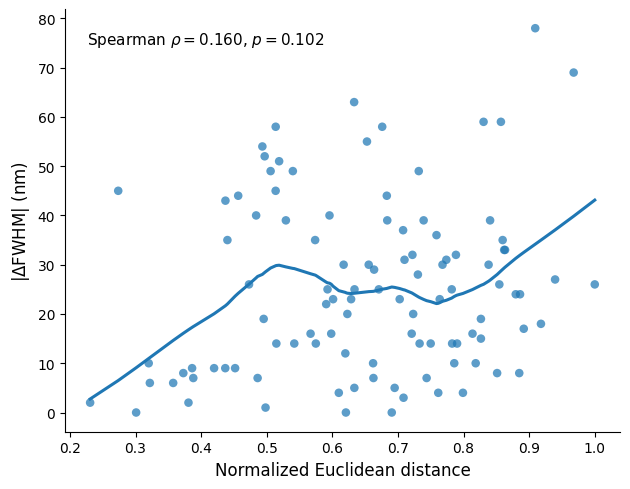


Figure 1 SVG：E:\desktop\Multiobjective Identification of Phosphor Materials via a Domain Knowledge Integrated Semisupervised Learning Framework\code\Prototype-base-cluster\GMM\GMM4\FWHM_pair_distance_figures\FWHM_distance_scatter_LOWESS.svg
Figure 1 PNG：E:\desktop\Multiobjective Identification of Phosphor Materials via a Domain Knowledge Integrated Semisupervised Learning Framework\code\Prototype-base-cluster\GMM\GMM4\FWHM_pair_distance_figures\FWHM_distance_scatter_LOWESS.png

Distance quartile statistics

Q1:
n = 27
Distance range = 0.2308 – 0.5146
Mean |ΔFWHM| = 22.56 nm
Median |ΔFWHM| = 10.00 nm

Q2:
n = 26
Distance range = 0.5189 – 0.6636
Mean |ΔFWHM| = 25.27 nm
Median |ΔFWHM| = 23.00 nm

Q3:
n = 26
Distance range = 0.6708 – 0.7826
Mean |ΔFWHM| = 24.88 nm
Median |ΔFWHM| = 25.00 nm

Q4:
n = 26
Distance range = 0.7858 – 1.0000
Mean |ΔFWHM| = 28.19 nm
Median |ΔFWHM| = 25.00 nm


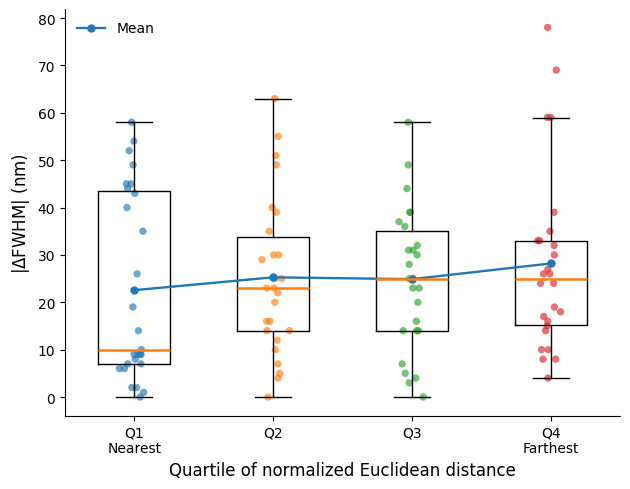


Figure 2 SVG：E:\desktop\Multiobjective Identification of Phosphor Materials via a Domain Knowledge Integrated Semisupervised Learning Framework\code\Prototype-base-cluster\GMM\GMM4\FWHM_pair_distance_figures\FWHM_distance_quartile_boxplot.svg
Figure 2 PNG：E:\desktop\Multiobjective Identification of Phosphor Materials via a Domain Knowledge Integrated Semisupervised Learning Framework\code\Prototype-base-cluster\GMM\GMM4\FWHM_pair_distance_figures\FWHM_distance_quartile_boxplot.png

Final summary
Number of pairs = 105
Spearman rho = 0.1604
Spearman p = 0.1021
Q1: mean |ΔFWHM| = 22.56 nm, median = 10.00 nm
Q2: mean |ΔFWHM| = 25.27 nm, median = 23.00 nm
Q3: mean |ΔFWHM| = 24.88 nm, median = 25.00 nm
Q4: mean |ΔFWHM| = 28.19 nm, median = 25.00 nm


In [9]:
# ============================================================
# Pairwise Euclidean distance vs FWHM difference
#




#    Figure 1: Normalized Euclidean distance vs |ΔFWHM|
#              Scatter + LOWESS smoothing
#    Figure 2: Distance quartile vs |ΔFWHM|
#              Boxplot + raw points + mean trend

#

#   Normalized_Euclidean_Distance
#   FWHM_Difference_nm
# ============================================================


# ============================================================

# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr


# ============================================================

# ============================================================


input_excel = Path(
    r"E:\desktop\Multiobjective Identification of Phosphor Materials via a Domain Knowledge Integrated Semisupervised Learning Framework\code\Prototype-base-cluster\GMM\GMM4\benchmark_distance_output\105Pair_FWHM_diff.xlsx"
)





# ============================================================

# ============================================================

figure_dir = Path.cwd() / "FWHM_pair_distance_figures"

figure_dir.mkdir(
    parents=True,
    exist_ok=True
)

print(
    f"：{figure_dir.resolve()}"
)


# ============================================================

# ============================================================

df = pd.read_excel(
    input_excel,
    sheet_name="Sheet1"
)

print("\nExcel。")
print(f"：{len(df)}")

print("\nExcel：")
for col in df.columns:
    print(col)


# ============================================================

# ============================================================

required_columns = [
    "Normalized_Euclidean_Distance",
    "FWHM_Difference_nm"
]

missing_columns = [
    col
    for col in required_columns
    if col not in df.columns
]

if missing_columns:

    raise ValueError(
        f"Excel：{missing_columns}\n"
        "Excel。"
    )


# ============================================================

# ============================================================

x = pd.to_numeric(
    df["Normalized_Euclidean_Distance"],
    errors="coerce"
).to_numpy()

y = pd.to_numeric(
    df["FWHM_Difference_nm"],
    errors="coerce"
).to_numpy()



valid_mask = (
    np.isfinite(x)
    &
    np.isfinite(y)
)

x = x[valid_mask]
y = y[valid_mask]


print(
    f"\npair：{len(x)}"
)


# ============================================================

# ============================================================

rho, p_value = spearmanr(
    x,
    y
)

print("\n==============================")
print("Spearman correlation")
print("==============================")

print(
    f"Spearman rho = {rho:.4f}"
)

print(
    f"p-value = {p_value:.4f}"
)


# ============================================================

# ============================================================





use_lowess = False

try:

    from statsmodels.nonparametric.smoothers_lowess import lowess

    lowess_result = lowess(
        endog=y,
        exog=x,


        frac=0.45,


        it=0,

        return_sorted=True
    )

    smooth_x = lowess_result[:, 0]
    smooth_y = lowess_result[:, 1]

    use_lowess = True

    print(
        "\nLOWESS smoothing: statsmodels LOWESS"
    )

except ImportError:

    print(
        "\n statsmodels。"
        "。"
    )

    order = np.argsort(x)

    xs = x[order]
    ys = y[order]


    window = max(
        9,
        len(xs) // 10
    )

    smooth_x = []
    smooth_y = []

    for i in range(
        len(xs)
    ):

        left = max(
            0,
            i - window // 2
        )

        right = min(
            len(xs),
            i + window // 2 + 1
        )

        smooth_x.append(
            xs[i]
        )

        smooth_y.append(
            np.median(
                ys[left:right]
            )
        )

    smooth_x = np.asarray(
        smooth_x
    )

    smooth_y = np.asarray(
        smooth_y
    )


# ============================================================
# 8. Figure 1
# Scatter + LOWESS
# ============================================================

fig, ax = plt.subplots(
    figsize=(6.4, 5.0)
)


# -------------------------

# -------------------------

ax.scatter(
    x,
    y,

    s=38,

    alpha=0.72,

    edgecolors="none"
)


# -------------------------
# LOWESS / smoothing curve
# -------------------------

ax.plot(
    smooth_x,
    smooth_y,

    linewidth=2.2
)


# -------------------------

# -------------------------

ax.set_xlabel(
    "Normalized Euclidean distance",
    fontsize=12
)

ax.set_ylabel(
    r"$|\Delta \mathrm{FWHM}|$ (nm)",
    fontsize=12
)


ax.tick_params(
    axis="both",
    labelsize=10
)


# -------------------------

# -------------------------

if p_value < 0.001:

    p_text = r"$p<0.001$"

else:

    p_text = fr"$p={p_value:.3f}$"


ax.text(
    0.04,
    0.95,

    fr"Spearman $\rho={rho:.3f}$, {p_text}",

    transform=ax.transAxes,

    fontsize=11,

    va="top"
)


# -------------------------

# -------------------------

ax.spines[
    "top"
].set_visible(
    False
)

ax.spines[
    "right"
].set_visible(
    False
)


fig.tight_layout()


# ============================================================

# ============================================================

svg_path_1 = (
    figure_dir
    /
    "FWHM_distance_scatter_LOWESS.svg"
)

png_path_1 = (
    figure_dir
    /
    "FWHM_distance_scatter_LOWESS.png"
)


fig.savefig(
    svg_path_1,

    format="svg",

    bbox_inches="tight"
)


fig.savefig(
    png_path_1,

    dpi=600,

    bbox_inches="tight"
)


plt.show()


print(
    f"\nFigure 1 SVG：{svg_path_1.resolve()}"
)

print(
    f"Figure 1 PNG：{png_path_1.resolve()}"
)


# ============================================================

# ============================================================


sort_idx = np.argsort(x)

n_samples = len(x)





rank_group = np.zeros(
    n_samples,
    dtype=int
)


for rank, original_index in enumerate(
    sort_idx
):

    group = int(
        rank * 4 / n_samples
    )

    group = min(
        group,
        3
    )

    rank_group[
        original_index
    ] = group


# Q1-Q4
groups = [

    y[
        rank_group == i
    ]

    for i in range(
        4
    )
]



distance_groups = [

    x[
        rank_group == i
    ]

    for i in range(
        4
    )
]


# ============================================================

# ============================================================

group_means = [

    np.mean(
        values
    )

    for values in groups
]


group_medians = [

    np.median(
        values
    )

    for values in groups
]


print(
    "\n=========================================="
)

print(
    "Distance quartile statistics"
)

print(
    "=========================================="
)


for i in range(
    4
):

    values = groups[i]

    distances = distance_groups[i]

    print(
        f"\nQ{i+1}:"
    )

    print(
        f"n = {len(values)}"
    )

    print(
        "Distance range = "
        f"{distances.min():.4f} – "
        f"{distances.max():.4f}"
    )

    print(
        "Mean |ΔFWHM| = "
        f"{np.mean(values):.2f} nm"
    )

    print(
        "Median |ΔFWHM| = "
        f"{np.median(values):.2f} nm"
    )


# ============================================================
# 12. Figure 2
# Distance quartile boxplot
# ============================================================

fig, ax = plt.subplots(
    figsize=(6.4, 5.0)
)


# -------------------------
# Boxplot
# -------------------------

boxplot_result = ax.boxplot(
    groups,

    positions=[
        1,
        2,
        3,
        4
    ],

    widths=0.52,

    showfliers=False,

    patch_artist=False,

    medianprops={
        "linewidth": 1.8
    }
)


# ============================================================

# ============================================================




rng = np.random.default_rng(
    42
)


for position, values in enumerate(
    groups,
    start=1
):

    jitter = rng.normal(
        loc=0,
        scale=0.055,
        size=len(values)
    )

    x_points = (
        np.full(
            len(values),
            position,
            dtype=float
        )
        +
        jitter
    )

    ax.scatter(
        x_points,
        values,

        s=28,

        alpha=0.65,

        edgecolors="none"
    )


# ============================================================

# ============================================================

ax.plot(
    [
        1,
        2,
        3,
        4
    ],

    group_means,

    marker="o",

    markersize=5,

    linewidth=1.7,

    label="Mean"
)


# ============================================================

# ============================================================

ax.set_xticks(
    [
        1,
        2,
        3,
        4
    ]
)


ax.set_xticklabels(
    [
        "Q1\nNearest",
        "Q2",
        "Q3",
        "Q4\nFarthest"
    ],

    fontsize=10
)


ax.set_xlabel(
    "Quartile of normalized Euclidean distance",
    fontsize=12
)


ax.set_ylabel(
    r"$|\Delta \mathrm{FWHM}|$ (nm)",
    fontsize=12
)


ax.tick_params(
    axis="y",
    labelsize=10
)


# -------------------------
# Legend
# -------------------------

ax.legend(
    frameon=False,

    fontsize=10
)


# -------------------------

# -------------------------

ax.spines[
    "top"
].set_visible(
    False
)

ax.spines[
    "right"
].set_visible(
    False
)


fig.tight_layout()


# ============================================================

# ============================================================

svg_path_2 = (
    figure_dir
    /
    "FWHM_distance_quartile_boxplot.svg"
)

png_path_2 = (
    figure_dir
    /
    "FWHM_distance_quartile_boxplot.png"
)


fig.savefig(
    svg_path_2,

    format="svg",

    bbox_inches="tight"
)


fig.savefig(
    png_path_2,

    dpi=600,

    bbox_inches="tight"
)


plt.show()


print(
    f"\nFigure 2 SVG：{svg_path_2.resolve()}"
)

print(
    f"Figure 2 PNG：{png_path_2.resolve()}"
)


# ============================================================

# ============================================================

print(
    "\n=========================================="
)

print(
    "Final summary"
)

print(
    "=========================================="
)


print(
    f"Number of pairs = {len(x)}"
)


print(
    f"Spearman rho = {rho:.4f}"
)


print(
    f"Spearman p = {p_value:.4f}"
)


for i in range(
    4
):

    print(
        f"Q{i+1}: "
        f"mean |ΔFWHM| = "
        f"{group_means[i]:.2f} nm, "
        f"median = "
        f"{group_medians[i]:.2f} nm"
    )